Dataset shape: (50000, 11)

Columns and dtypes:
Model                    object
Year                    float64
Region                   object
Color                    object
Fuel_Type                object
Transmission             object
Engine_Size_L           float64
Mileage_KM              float64
Price_USD               float64
Sales_Volume            float64
Sales_Classification     object
dtype: object

Missing values per column:
Model                   1512
Year                    1514
Region                  1512
Color                   1465
Fuel_Type               1518
Transmission            1549
Engine_Size_L           1507
Mileage_KM              1500
Price_USD               1511
Sales_Volume            1441
Sales_Classification       0
dtype: int64
--- Feature Classification ---
     Feature     Level                                                                       Justification
0      Model   Nominal                  Categorical nominal: model names identify catego

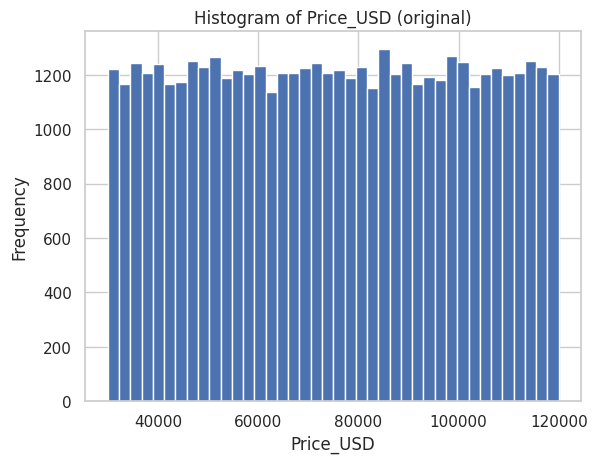

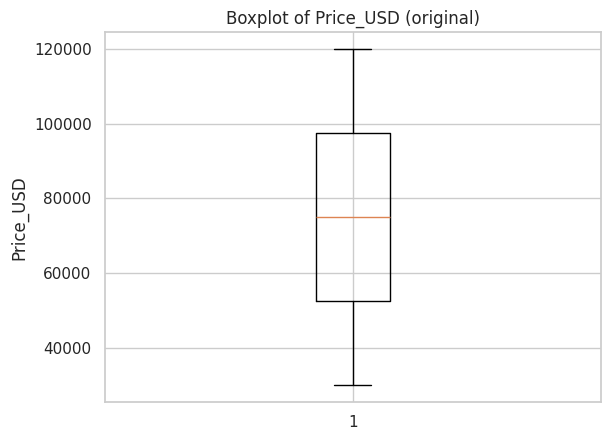

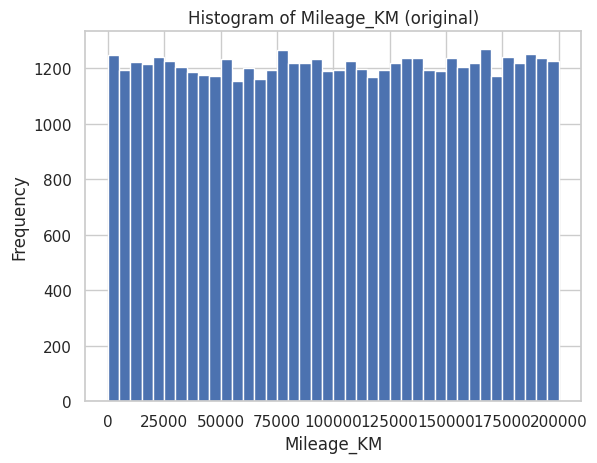

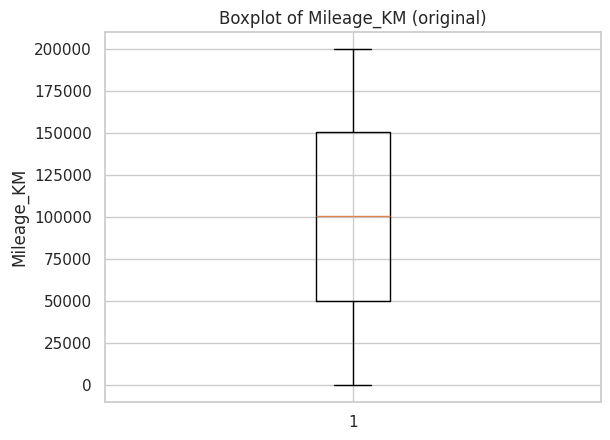


Price_USD -> Q1=53081.50, Q3=96860.50, IQR=43779.00, lower=-12587.00, upper=162529.00, outliers=0

Mileage_KM -> Q1=51541.75, Q3=149075.50, IQR=97533.75, lower=-94758.88, upper=295376.12, outliers=0


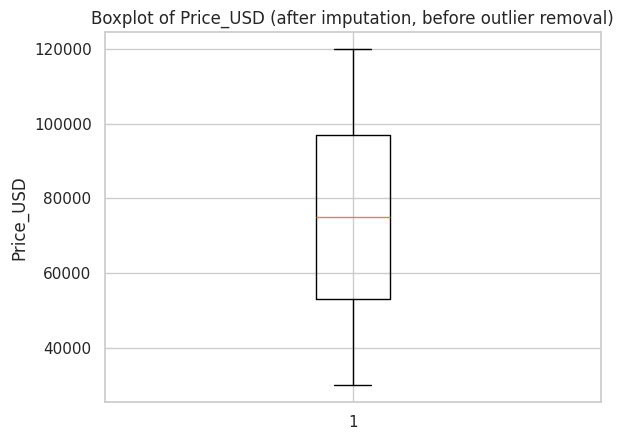

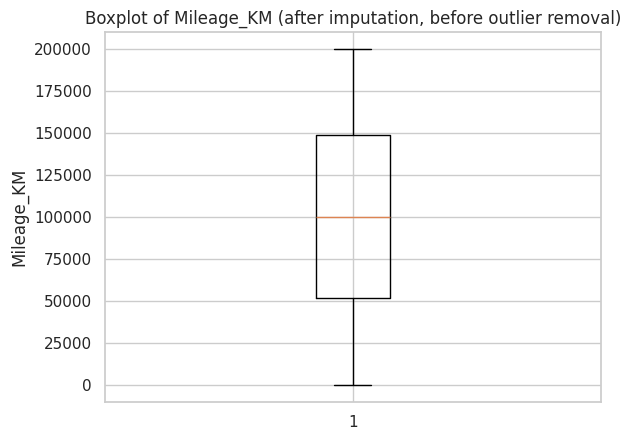

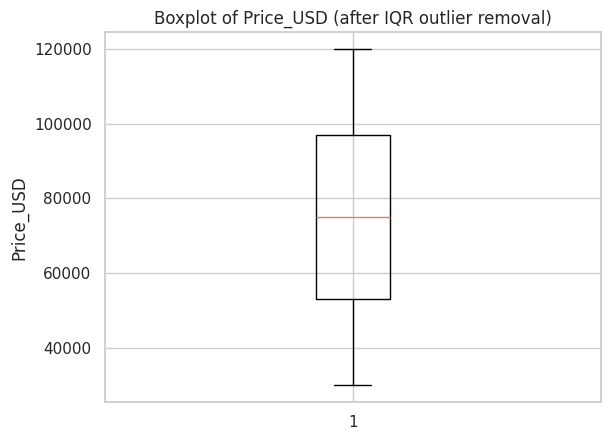

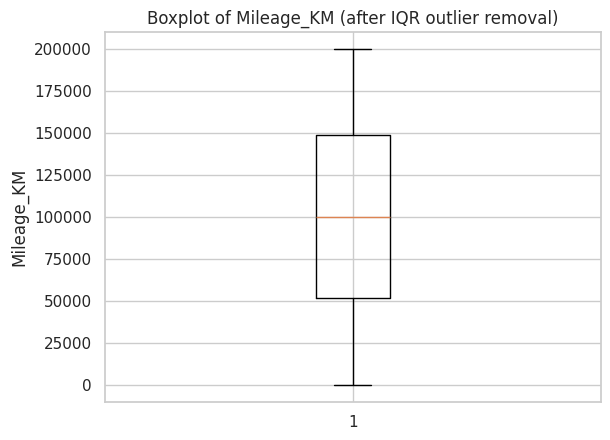


Price_USD mean before=75024.30, after=75024.30
Price_USD range before=89998.00, after=89998.00

Mileage_KM mean before=100279.15, after=100279.15
Mileage_KM range before=199993.00, after=199993.00

Top 10 Price_USD records (to inspect potential meaningful outliers):
--- Top prices sample ---
          Model    Year       Region  Price_USD
26071        i8  2017.0  Middle East   119998.0
38158        X6  2019.0         Asia   119997.0
6862         i8  2024.0       Africa   119997.0
154          X1  2016.0       Africa   119996.0
6271   3 Series  2019.0  Middle East   119994.0



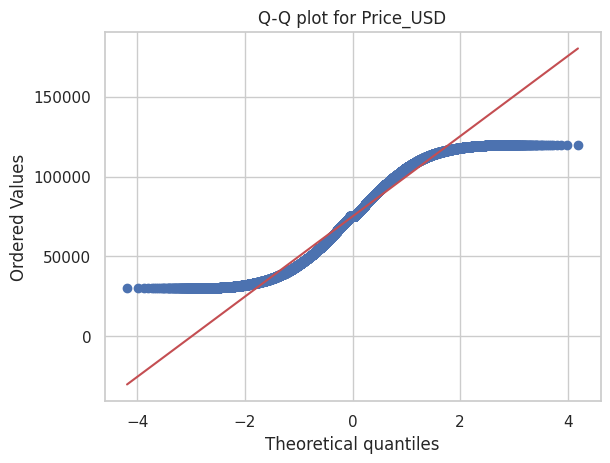


Skewness for Price_USD: -0.000  |  Kurtosis: -1.145


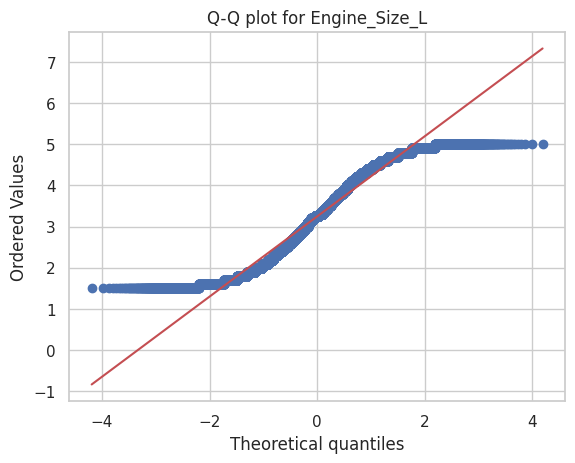


Skewness for Engine_Size_L: -0.001  |  Kurtosis: -1.141

Correlation matrix:
               Engine_Size_L  Mileage_KM  Price_USD  Sales_Volume      Year
Engine_Size_L       1.000000   -0.005576   0.001544     -0.003174  0.000561
Mileage_KM         -0.005576    1.000000  -0.003850      0.000475  0.008101
Price_USD           0.001544   -0.003850   1.000000      0.001384  0.002126
Sales_Volume       -0.003174    0.000475   0.001384      1.000000  0.001816
Year                0.000561    0.008101   0.002126      0.001816  1.000000


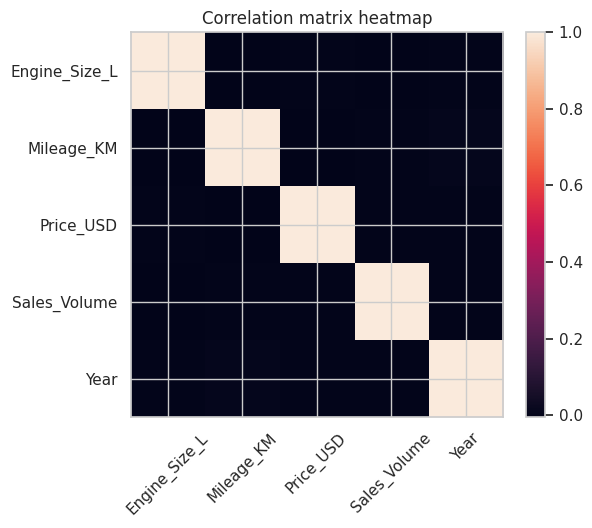


Strongest negative correlation: -0.0056 between ('Engine_Size_L', 'Mileage_KM')
Strongest positive correlation: 0.0081 between ('Year', 'Mileage_KM')


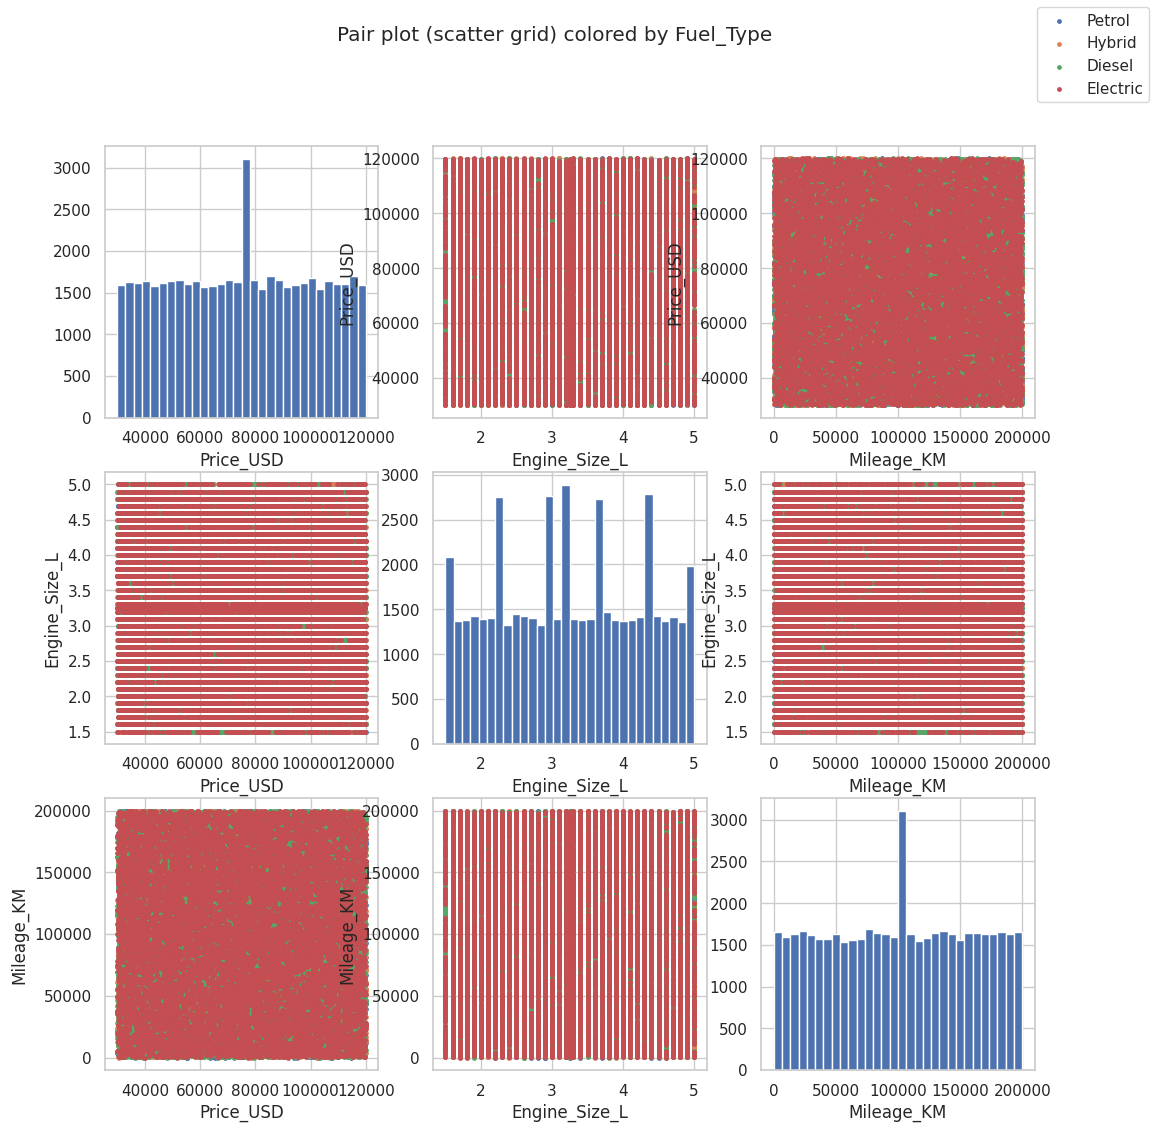


Electric sample size: 12102  |  Diesel sample size: 11878

Two-sample t-test (Electric vs Diesel) on Price_USD (Welch's t-test):
t-statistic = 0.2666, p-value = 7.8979e-01
Result: Fail to reject H0 -> No significant difference detected at α=0.05.

95% CI for mean Price_USD (Year > 2020): mean=75111.43, CI=(74673.97, 75548.89), n=13101
Margin of error for Mileage_KM at 90%: 419.69 (mean=100279.15, n=50000)
Margin of error for Mileage_KM at 95%: 500.09 (mean=100279.15, n=50000)
Margin of error for Mileage_KM at 99%: 657.24 (mean=100279.15, n=50000)

Sales_Volume samples: Europe n=8081, Asia n=9717
t-statistic = 0.5727, p-value = 5.6685e-01
Result: No significant difference detected between Europe and Asia.


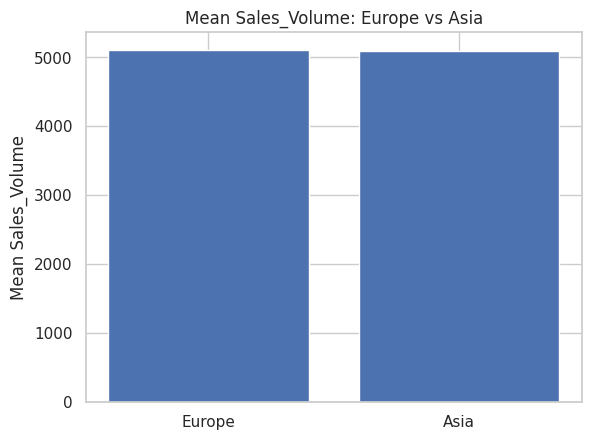


SUV sample size: 17465
One-sample t-test (SUV mean > $70000): t = 25.1003, one-sided p = 0.0000e+00
Reject H0: SUVs have mean Price_USD significantly greater than $70,000 at α=0.05

Linear regression result: Price_USD = 74895.30 + (39.73) * Engine_Size_L
R-squared: 0.0000


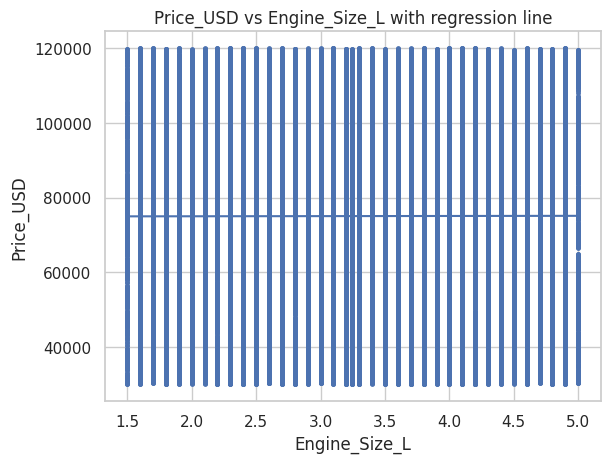

Interpretation: Holding other factors constant, each additional 1 L in engine size associates with an average price change of $39.73.

Cleaned dataset saved to: bmw_sales_cleaned.csv
--- descriptive_numeric ---
                 count           mean           std      min       25%       50%       75%       max      mode     range  skewness
Year           48486.0    2017.017943      4.324061   2010.0   2013.00    2017.0    2021.0    2024.0    2022.0      14.0 -0.002122
Engine_Size_L  48493.0       3.246897      1.009761      1.5      2.40       3.2       4.1       5.0       3.8       3.5 -0.000786
Mileage_KM     48500.0  100279.150433  57928.233713      3.0  50140.25  100425.0  150578.0  199996.0  136842.0  199993.0 -0.008407
Price_USD      48489.0   75024.301553  25993.075758  30000.0  52430.00   75016.0   97623.0  119998.0   30948.0   89998.0 -0.000064
Sales_Volume   48559.0    5066.855825   2855.939657    100.0   2590.00    5089.0    7536.0    9999.0    9502.0    9899.0 -0.011607

--

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patches
from pandas.plotting import scatter_matrix
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import math
import warnings
warnings.filterwarnings('ignore')

try:
    from caas_jupyter_tools import display_dataframe_to_user
    def show_df(name, df):
        display_dataframe_to_user(name, df)
except Exception:
    def show_df(name, df):
        print(f"--- {name} ---")
        print(df.head().to_string())
        print("")

file_path = "Set 22 - Dataset-BMW-sales-data.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns and dtypes:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())



# 1. Feature classification
feature_classes = {
    'Model': ('Nominal', 'Categorical nominal: model names identify categories without order'),
    'Year': ('Interval', 'Year is interval-level: differences are meaningful, no true zero in calendar years'),
    'Region': ('Nominal', 'Categorical nominal: regions are unordered labels'),
    'Color': ('Nominal', 'Categorical nominal: colour names unordered'),
    'Fuel_Type': ('Nominal', 'Categorical nominal: fuel categories unordered'),
    'Transmission': ('Nominal', 'Categorical nominal'),
    'Engine_Size_L': ('Ratio', 'Ratio: numeric with meaningful zero (0 L hypothetical) and ratios meaningful'),
    'Mileage_KM': ('Ratio', 'Ratio: kilometres driven has true zero and ratios meaningful'),
    'Price_USD': ('Ratio', 'Ratio: price has meaningful zero and ratios meaningful'),
    'Sales_Volume': ('Ratio', 'Count of cars sold — ratio'),
    'Sales_Classification': ('Ordinal', 'High/Medium/Low has order (High > Medium > Low)')
}

fc_df = pd.DataFrame.from_dict(feature_classes, orient='index', columns=['Level','Justification']).reset_index().rename(columns={'index':'Feature'})
show_df("Feature Classification", fc_df)

# 2. Descriptive statistics summary
numeric_cols = ['Year','Engine_Size_L','Mileage_KM','Price_USD','Sales_Volume']
desc = df[numeric_cols].describe().T[['count','mean','std','min','25%','50%','75%','max']]
modes = {}
for c in numeric_cols:
    vals = df[c].dropna()
    try:
        modes[c] = float(vals.mode().iloc[0]) if not vals.mode().empty else np.nan
    except:
        modes[c] = np.nan
desc['mode'] = pd.Series(modes)
desc['range'] = desc['max'] - desc['min']
desc['skewness'] = df[numeric_cols].skew()
show_df("Descriptive Statistics (numeric)", desc)

print("\nWhich measure best describes each variable? (based on skewness):")
for c in numeric_cols:
    skew = desc.loc[c,'skewness']
    if abs(skew) < 0.5:
        best = 'mean (data approximately symmetric)'
    elif skew > 0.5:
        best = 'median (right-skewed)'
    else:
        best = 'median (left-skewed)'
    print(f"- {c}: skew={skew:.3f} -> {best}")

# 3. Data Integrity & Cleaning
print("\nInitial missing values:")
print(df.isna().sum())

df_original = df.copy()

categorical_cols = ['Model','Region','Color','Fuel_Type','Transmission']
for col in categorical_cols:
    if col in df.columns:
        mode_val = df[col].mode().iloc[0]
        df[col].fillna(mode_val, inplace=True)

if 'Year' in df.columns:
    df['Year'].fillna(df['Year'].median(), inplace=True)

if 'Engine_Size_L' in df.columns:
    df['Engine_Size_L'].fillna(df['Engine_Size_L'].mean(), inplace=True)

if 'Mileage_KM' in df.columns:
    df['Mileage_KM'].fillna(df['Mileage_KM'].mean(), inplace=True)

if 'Price_USD' in df.columns:
    df['Price_USD'].fillna(df['Price_USD'].mean(), inplace=True)

if 'Sales_Volume' in df.columns:
    df['Sales_Volume'].fillna(df['Sales_Volume'].median(), inplace=True)

before_dups = df.shape[0]
df.drop_duplicates(inplace=True)
after_dups = df.shape[0]
print(f"\nRemoved {before_dups - after_dups} exact duplicate rows.")

print("\nMissing values after imputation:")
print(df.isna().sum())

show_df("Cleaned (imputed) preview", df.head(10))

# 4. Distribution analysis and outlier impact
vars_to_check = ['Price_USD','Mileage_KM']

for var in vars_to_check:
    plt.figure()
    plt.hist(df_original[var].dropna(), bins=40)
    plt.title(f'Histogram of {var} (original)')
    plt.xlabel(var)
    plt.ylabel('Frequency')
    plt.show()

    plt.figure()
    plt.boxplot(df_original[var].dropna(), vert=True)
    plt.title(f'Boxplot of {var} (original)')
    plt.ylabel(var)
    plt.show()

outlier_summary = {}
for var in vars_to_check:
    series = df[var].dropna()
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    outlier_summary[var] = {'Q1':Q1,'Q3':Q3,'IQR':IQR,'lower':lower,'upper':upper,'n_outliers':len(outliers)}
    print(f"\n{var} -> Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, lower={lower:.2f}, upper={upper:.2f}, outliers={len(outliers)}")

df_trimmed = df.copy()
for var in vars_to_check:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_trimmed = df_trimmed[(df_trimmed[var] >= lower) & (df_trimmed[var] <= upper)]

for var in vars_to_check:
    plt.figure()
    plt.boxplot(df[var].dropna(), vert=True)
    plt.title(f'Boxplot of {var} (after imputation, before outlier removal)')
    plt.ylabel(var)
    plt.show()

for var in vars_to_check:
    plt.figure()
    plt.boxplot(df_trimmed[var].dropna(), vert=True)
    plt.title(f'Boxplot of {var} (after IQR outlier removal)')
    plt.ylabel(var)
    plt.show()

for var in vars_to_check:
    mean_before = df[var].mean()
    mean_after = df_trimmed[var].mean()
    range_before = df[var].max() - df[var].min()
    range_after = df_trimmed[var].max() - df_trimmed[var].min()
    print(f"\n{var} mean before={mean_before:.2f}, after={mean_after:.2f}")
    print(f"{var} range before={range_before:.2f}, after={range_after:.2f}")

print("\nTop 10 Price_USD records (to inspect potential meaningful outliers):")
top_prices = df.sort_values('Price_USD', ascending=False).head(10)[['Model','Year','Region','Price_USD']]
show_df("Top prices sample", top_prices)

# 5. Normality assessment (Q-Q plots)
for var in ['Price_USD','Engine_Size_L']:
    plt.figure()
    stats.probplot(df[var].dropna(), dist="norm", plot=plt)
    plt.title(f"Q-Q plot for {var}")
    plt.show()
    print(f"\nSkewness for {var}: {df[var].skew():.3f}  |  Kurtosis: {df[var].kurtosis():.3f}")

# 6. Correlation
corr_vars = ['Engine_Size_L','Mileage_KM','Price_USD','Sales_Volume','Year']
corr = df[corr_vars].corr()
print("\nCorrelation matrix:")
print(corr)

plt.figure(figsize=(6,5))
plt.imshow(corr, aspect='auto')
plt.colorbar()
plt.xticks(range(len(corr_vars)), corr_vars, rotation=45)
plt.yticks(range(len(corr_vars)), corr_vars)
plt.title("Correlation matrix heatmap")
plt.show()

corr_unstack = corr.unstack().dropna()
corr_unstack = corr_unstack[corr_unstack.index.get_level_values(0) != corr_unstack.index.get_level_values(1)]
sorted_corr = corr_unstack.sort_values()
strongest_negative = sorted_corr.iloc[0]
strongest_positive = sorted_corr.iloc[-1]
print(f"\nStrongest negative correlation: {strongest_negative:.4f} between {sorted_corr.index[0]}")
print(f"Strongest positive correlation: {strongest_positive:.4f} between {sorted_corr.index[-1]}")

# 7. Pair plot
pair_vars = ['Price_USD','Engine_Size_L','Mileage_KM']
fuel_types = df['Fuel_Type'].unique()
n = len(pair_vars)
fig, axes = plt.subplots(n, n, figsize=(12,12))
for i in range(n):
    for j in range(n):
        ax = axes[i,j]
        if i == j:
            ax.hist(df[pair_vars[i]].dropna(), bins=30)
            ax.set_xlabel(pair_vars[i])
        else:
            for ft in fuel_types:
                sub = df[df['Fuel_Type']==ft]
                ax.scatter(sub[pair_vars[j]], sub[pair_vars[i]], s=6, label=str(ft))
            ax.set_xlabel(pair_vars[j])
            ax.set_ylabel(pair_vars[i])

handles, labels = axes[0,1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')
plt.suptitle("Pair plot (scatter grid) colored by Fuel_Type")
plt.show()

# 1. Two-sample t-test
group_electric = df[df['Fuel_Type']=='Electric']['Price_USD'].dropna()
group_diesel = df[df['Fuel_Type']=='Diesel']['Price_USD'].dropna()

print(f"\nElectric sample size: {len(group_electric)}  |  Diesel sample size: {len(group_diesel)}")
t_stat, p_val = stats.ttest_ind(group_electric, group_diesel, equal_var=False, nan_policy='omit')
print("\nTwo-sample t-test (Electric vs Diesel) on Price_USD (Welch's t-test):")
print(f"t-statistic = {t_stat:.4f}, p-value = {p_val:.4e}")
alpha = 0.05
if p_val < alpha:
    print("Result: Reject H0 -> There is a significant difference in mean Price_USD between Electric and Diesel at α=0.05.")
else:
    print("Result: Fail to reject H0 -> No significant difference detected at α=0.05.")

# 2. 95% CI
after_2020 = df[df['Year'] > 2020]['Price_USD'].dropna()
n = len(after_2020)
mean_ = after_2020.mean()
se = after_2020.std(ddof=1)/math.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n-1)
ci_low = mean_ - t_crit*se
ci_high = mean_ + t_crit*se
print(f"\n95% CI for mean Price_USD (Year > 2020): mean={mean_:.2f}, CI=({ci_low:.2f}, {ci_high:.2f}), n={n}")

# Margin of error
mk = df['Mileage_KM'].dropna()
n_mk = len(mk)
mean_mk = mk.mean()
sd_mk = mk.std(ddof=1)
for conf in [0.90, 0.95, 0.99]:
    alpha = 1-conf
    t_c = stats.t.ppf(1-alpha/2, df=n_mk-1)
    me = t_c * sd_mk / math.sqrt(n_mk)
    print(f"Margin of error for Mileage_KM at {int(conf*100)}%: {me:.2f} (mean={mean_mk:.2f}, n={n_mk})")

# 3. Regional sales comparison
region_a = 'Europe'
region_b = 'Asia'
if 'Region' in df.columns:
    grp_a = df[df['Region']==region_a]['Sales_Volume'].dropna()
    grp_b = df[df['Region']==region_b]['Sales_Volume'].dropna()
    print(f"\nSales_Volume samples: {region_a} n={len(grp_a)}, {region_b} n={len(grp_b)}")
    t_stat_r, p_val_r = stats.ttest_ind(grp_a, grp_b, equal_var=False, nan_policy='omit')
    print(f"t-statistic = {t_stat_r:.4f}, p-value = {p_val_r:.4e}")
    if p_val_r < 0.05:
        print(f"Result: Significant difference in mean Sales_Volume between {region_a} and {region_b}.")
    else:
        print(f"Result: No significant difference detected between {region_a} and {region_b}.")
    means = [grp_a.mean(), grp_b.mean()]
    plt.figure()
    plt.bar([region_a, region_b], means)
    plt.ylabel('Mean Sales_Volume')
    plt.title('Mean Sales_Volume: Europe vs Asia')
    plt.show()
else:
    print("Region column not found; skipping regional comparison.")

# 1. Price benchmark test
def is_suv(model):
    try:
        m = str(model).strip().upper()
        return m.startswith('X') or (' X' in m) or (len(m)>1 and m[0]=='X' and m[1].isdigit())
    except:
        return False

df['Is_SUV'] = df['Model'].apply(is_suv)
suv_prices = df[df['Is_SUV']==True]['Price_USD'].dropna()
print(f"\nSUV sample size: {len(suv_prices)}")

mu0 = 70000
t_stat_suv, p_val_suv = stats.ttest_1samp(suv_prices, popmean=mu0, alternative='greater') if hasattr(stats, 'ttest_1samp') and 'alternative' in stats.ttest_1samp.__code__.co_varnames else ( (suv_prices.mean()-mu0) / (suv_prices.std(ddof=1)/math.sqrt(len(suv_prices))), None )

if p_val_suv is None:
    t_stat_suv = (suv_prices.mean()-mu0) / (suv_prices.std(ddof=1)/math.sqrt(len(suv_prices)))
    p_one_sided = 1 - stats.t.cdf(t_stat_suv, df=len(suv_prices)-1)
else:
    p_one_sided = p_val_suv

print(f"One-sample t-test (SUV mean > ${mu0}): t = {t_stat_suv:.4f}, one-sided p = {p_one_sided:.4e}")
alpha = 0.05
if p_one_sided < alpha:
    print("Reject H0: SUVs have mean Price_USD significantly greater than $70,000 at α=0.05")
else:
    print("Fail to reject H0: No evidence that SUV mean price exceeds $70,000")

# 2. Regression
reg_df = df[['Engine_Size_L','Price_USD']].dropna()
X = reg_df[['Engine_Size_L']].values
y = reg_df['Price_USD'].values

model = LinearRegression()
model.fit(X,y)
beta0 = model.intercept_
beta1 = model.coef_[0]
y_pred = model.predict(X)
r2 = r2_score(y, y_pred)

print(f"\nLinear regression result: Price_USD = {beta0:.2f} + ({beta1:.2f}) * Engine_Size_L")
print(f"R-squared: {r2:.4f}")

plt.figure()
plt.scatter(X, y, s=6)
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)
y_line = model.predict(x_line)
plt.plot(x_line, y_line)
plt.xlabel('Engine_Size_L')
plt.ylabel('Price_USD')
plt.title('Price_USD vs Engine_Size_L with regression line')
plt.show()

print(f"Interpretation: Holding other factors constant, each additional 1 L in engine size associates with an average price change of ${beta1:.2f}.")

cleaned_path = "bmw_sales_cleaned.csv"
df.to_csv(cleaned_path, index=False)
print(f"\nCleaned dataset saved to: {cleaned_path}")

summary_tables = {
    'descriptive_numeric': desc,
    'correlation_matrix': corr,
    'outlier_summary': pd.DataFrame(outlier_summary).T
}

for name, table in summary_tables.items():
    try:
        show_df(name, table)
    except Exception:
        print(f"\n{name}:\n{table}\n")

print("\n--- End of analysis script ---")